<a href="https://colab.research.google.com/github/annjerinsundar-code/ICTAK-AI-ML-Coursework/blob/main/UnsupervisedLearning_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage

np.random.seed(42)

In [2]:
# Load dataset
df = pd.read_csv("/content/adult_dataset.csv")
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [3]:
# Understanding the data
print("Shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
print("-----------------------------------------")
df.info()

print("\n\nDataset Statistical summary:")
print("----------------------------------------------------------------------------------")
df.describe()

Shape: (48842, 15)

Column names:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Dataset information:
-----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  c

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [4]:
# VISUALIZING DATASET

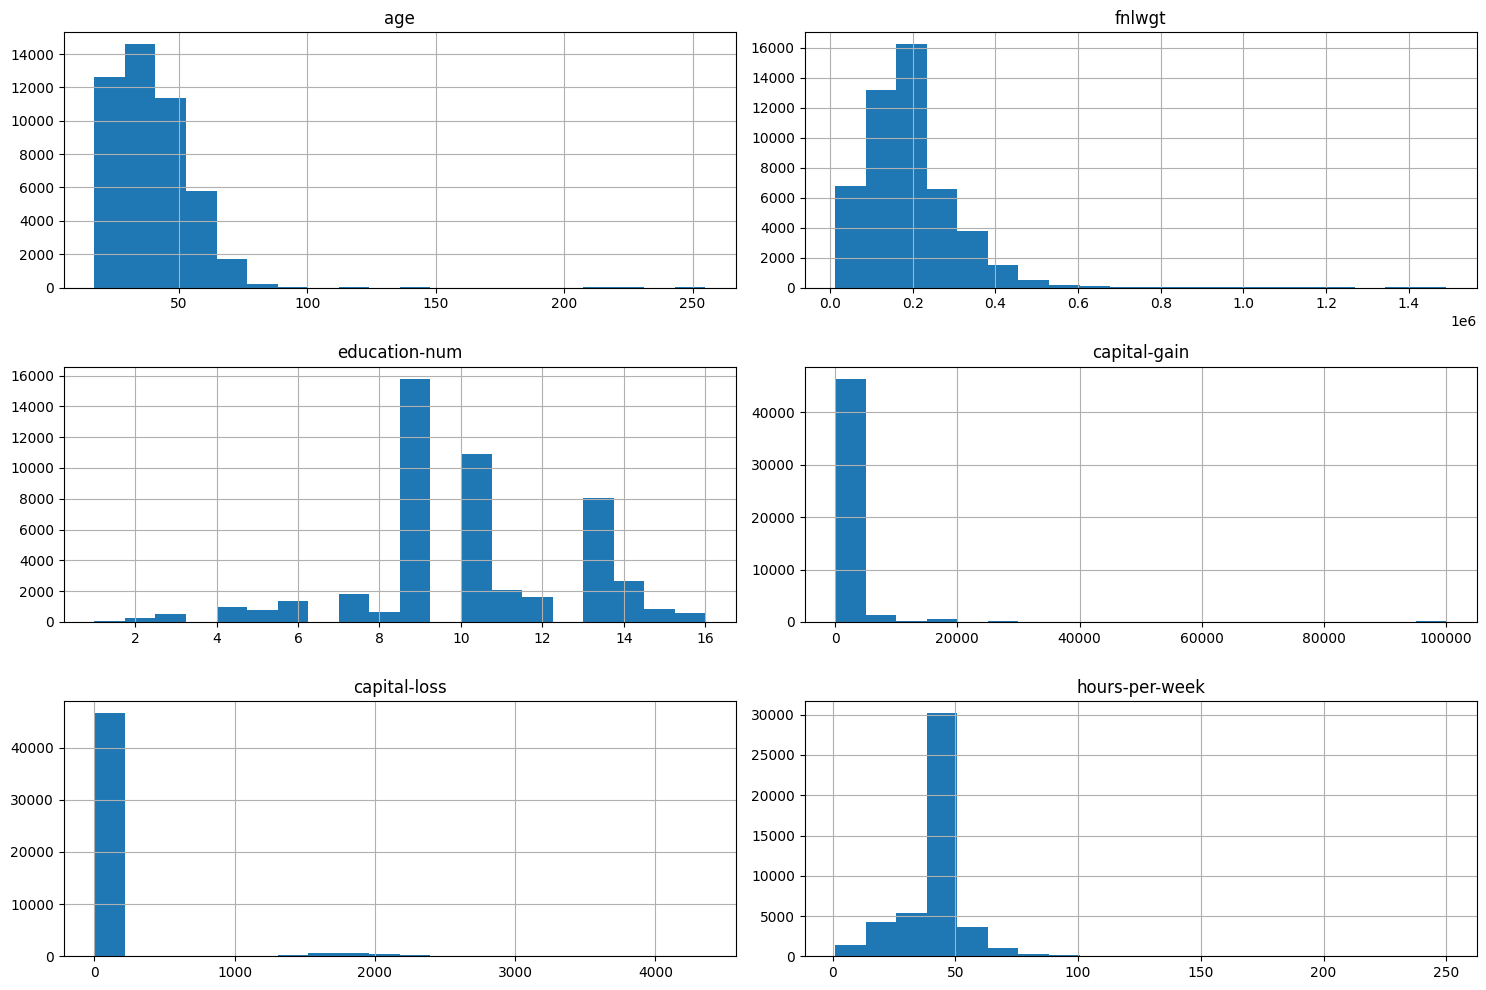

In [5]:
# Distribution of numerical features
df.select_dtypes(include=np.number).hist(figsize=(15, 10), bins=20)
plt.tight_layout()
plt.show()

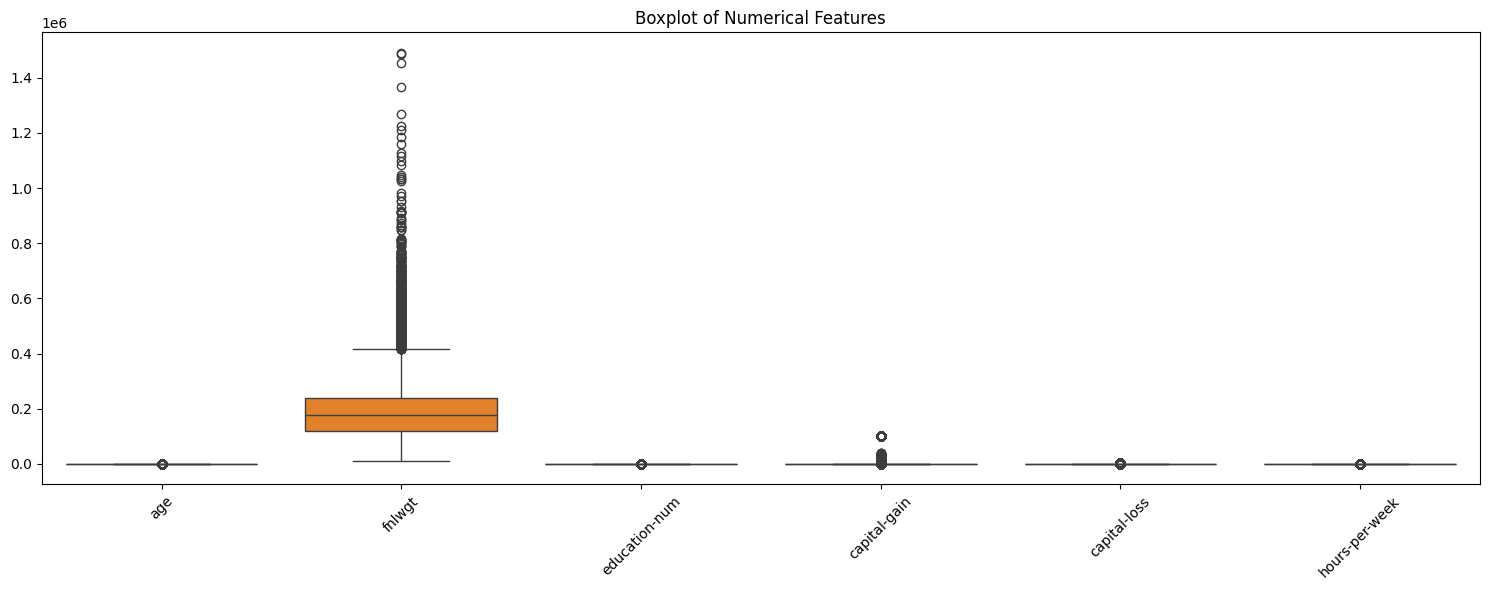

In [6]:
# Boxplots of numerical features
plt.figure(figsize=(15, 6))
sns.boxplot(data=df.select_dtypes(include=np.number))
plt.xticks(rotation=45)
plt.title("Boxplot of Numerical Features")
plt.tight_layout()
plt.show()

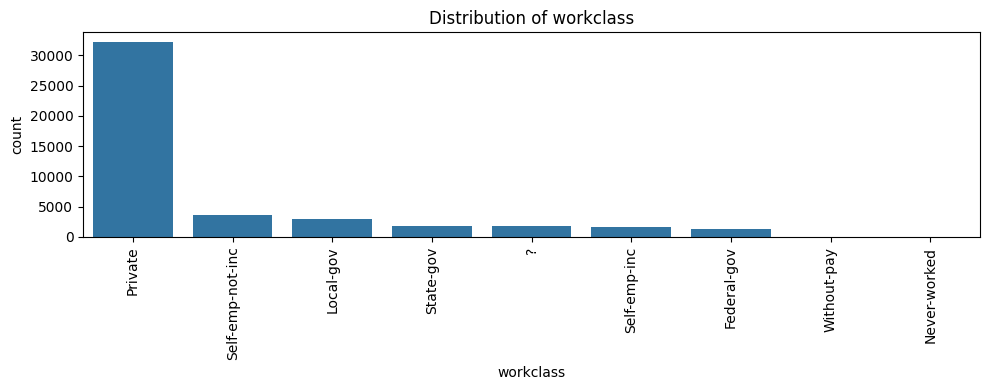

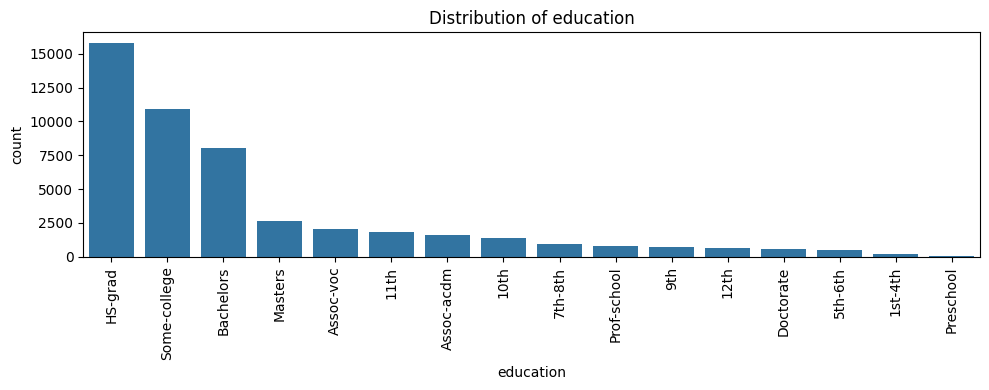

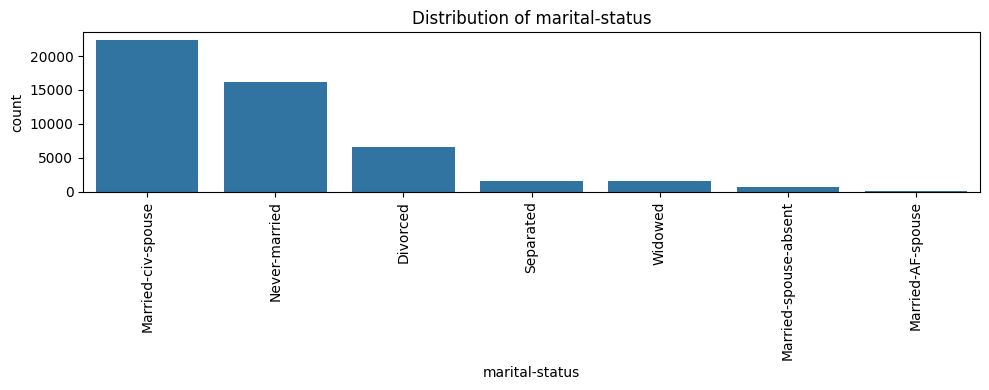

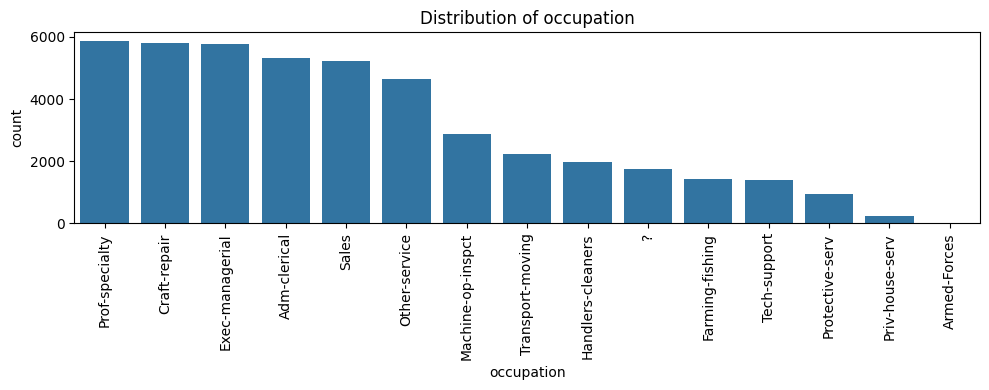

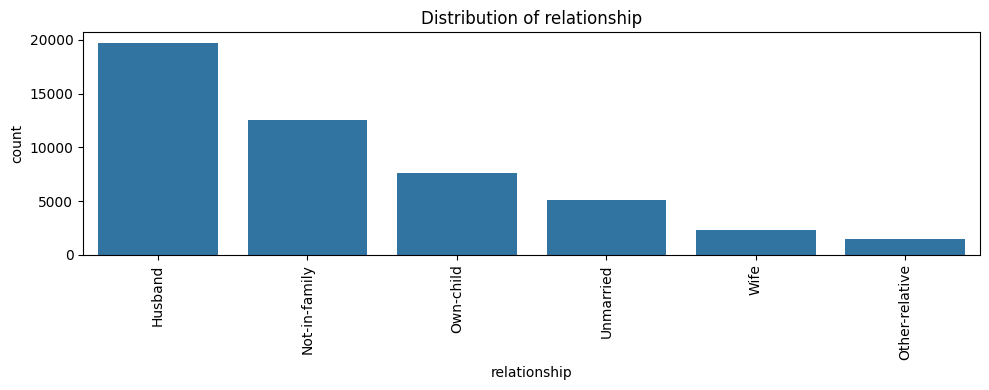

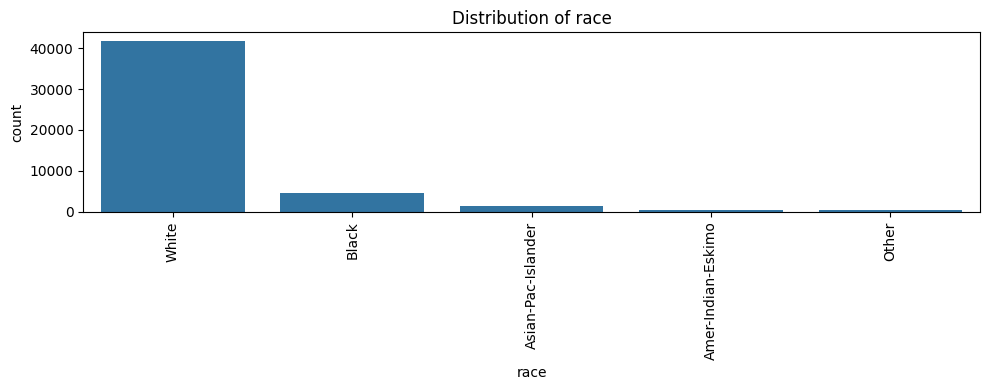

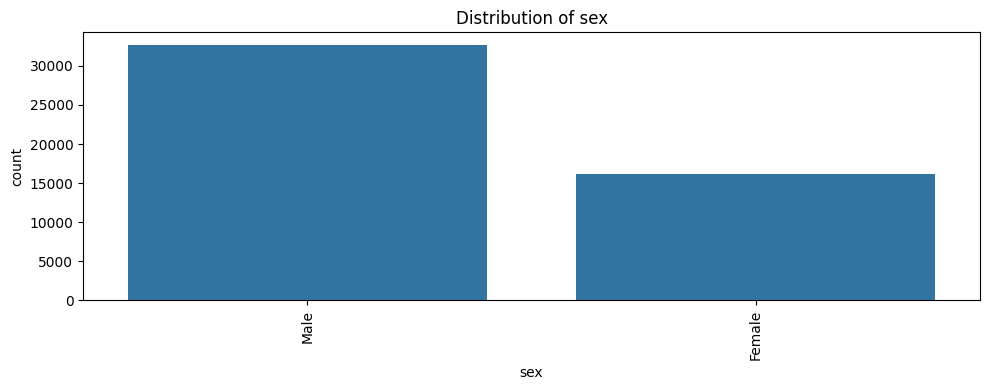

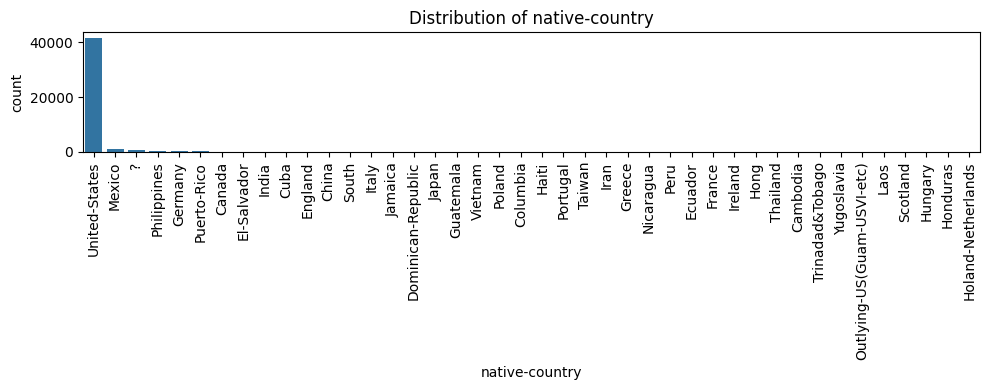

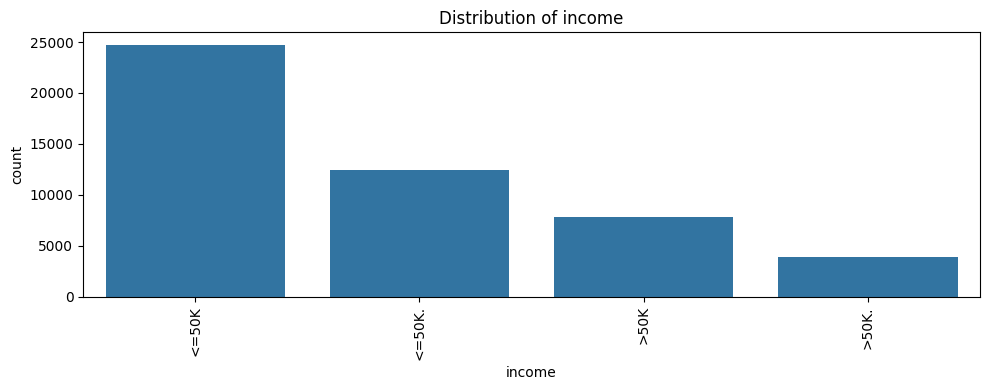

In [7]:
# Distribution of categorical features
for column in df.select_dtypes(include='object').columns:
    plt.figure(figsize=(10, 4))
    sns.countplot(data=df, x=column,
                  order=df[column].value_counts().index)
    plt.title("Distribution of " + column)
    plt.xticks(rotation=90)
    plt.tight_layout()
    plt.show()

In [8]:
print("Missing values in each column:")
print(df.isnull().sum())

Missing values in each column:
age               2442
workclass         3362
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        3357
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    2705
income               0
dtype: int64


In [9]:
print("Number of '?' values in each column:")
for column in df.select_dtypes(include='object').columns:
    print(column, ":", (df[column].astype(str).str.strip() == '?').sum())

Number of '?' values in each column:
workclass : 1763
education : 0
marital-status : 0
occupation : 1758
relationship : 0
race : 0
sex : 0
native-country : 555
income : 0


In [10]:
# DATA PREPROCESSING

In [11]:
# Remove Income column
original_df = df.copy()

# Drop income before clustering
df = df.drop('income', axis=1)

print("Shape after dropping income:", df.shape)
df.head()

Shape after dropping income: (48842, 14)


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba


In [12]:
# Replace '?' with missing values
df.replace('?', np.nan, inplace=True)

print("Missing values after replacing '?':")
print(df.isnull().sum())

Missing values after replacing '?':
age               2442
workclass         5125
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        5115
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week    2442
native-country    3260
dtype: int64


In [13]:
# Handle missing values
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(include='object').columns.tolist()

for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

print("Missing values after imputation:")
print(df.isnull().sum())

Missing values after imputation:
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
dtype: int64


In [14]:
# Detect outliers using the IQR method
outlier_counts = {}

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    count = ((df[column] < lower_bound) | (df[column] > upper_bound)).sum()
    outlier_counts[column] = count

outlier_summary = pd.DataFrame.from_dict(
    outlier_counts, orient='index', columns=['Number of Outliers']
)
outlier_summary

,Number of Outliers
age,364
fnlwgt,1453
education-num,1794
capital-gain,4035
capital-loss,2282
hours-per-week,12838


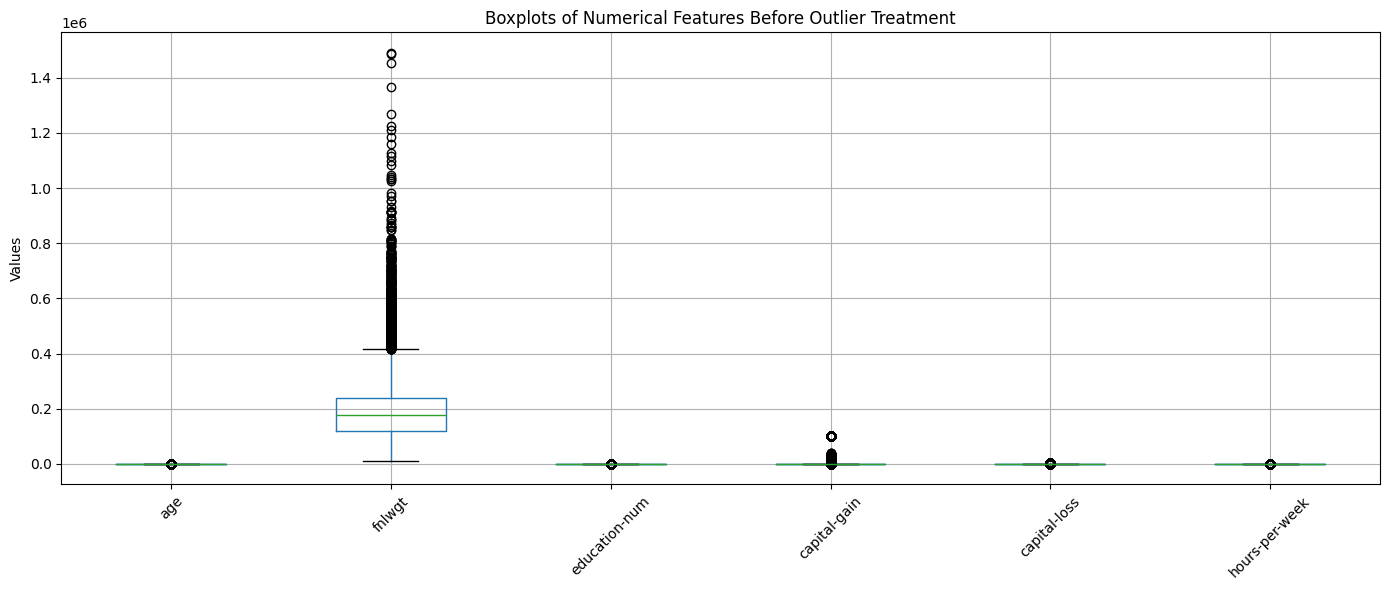

In [15]:
plt.figure(figsize=(14, 6))
df[numerical_columns].boxplot(rot=45)
plt.title("Boxplots of Numerical Features Before Outlier Treatment")
plt.ylabel("Values")
plt.tight_layout()
plt.show()

In [16]:
# Cap numerical outliers using the IQR lower and upper limits

for column in numerical_columns:
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    if IQR > 0:
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        df[column] = df[column].clip(
            lower=lower_bound,
            upper=upper_bound
        )
    else:
        print("IQR is zero for", column,
              "- Outlier treatment skipped.")

print("Outlier treatment completed using IQR capping.")

IQR is zero for capital-gain - Outlier treatment skipped.
IQR is zero for capital-loss - Outlier treatment skipped.
Outlier treatment completed using IQR capping.


In [17]:
# encode categorical variables using One-Hot Encoding
encoder = OneHotEncoder(handle_unknown='ignore')
encoded_array = encoder.fit_transform(df[categorical_columns]).toarray()

encoded_columns = encoder.get_feature_names_out(categorical_columns)
encoded_df = pd.DataFrame(encoded_array, columns=encoded_columns, index=df.index)

# Combine numerical and encoded categorical features
processed_df = pd.concat([df[numerical_columns], encoded_df], axis=1)

print("Shape after One-Hot Encoding:", processed_df.shape)
processed_df.head()

Shape after One-Hot Encoding: (48842, 105)


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Never-worked,workclass_Private,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39.0,77516.0,13.0,2174,0,40.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,50.0,83311.0,13.0,0,0,32.5,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,38.0,215646.0,9.0,0,0,40.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,53.0,234721.0,7.0,0,0,40.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,28.0,338409.0,13.0,0,0,40.0,0.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [18]:
# Scale the features using StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(processed_df)

print("Scaled data shape:", scaled_features.shape)
print("Scaled data is ready for clustering.")

Scaled data shape: (48842, 105)
Scaled data is ready for clustering.


In [19]:
#Preprocessing summary
print("Original dataset shape:", original_df.shape)
print("Dataset used for clustering:", processed_df.shape)
print("Income included in clustering:", 'income' in processed_df.columns)
print("Any missing values in processed data:", processed_df.isnull().sum().sum())

Original dataset shape: (48842, 15)
Dataset used for clustering: (48842, 105)
Income included in clustering: False
Any missing values in processed data: 0


In [20]:
# EXPLORATORY DATA ANALYSIS

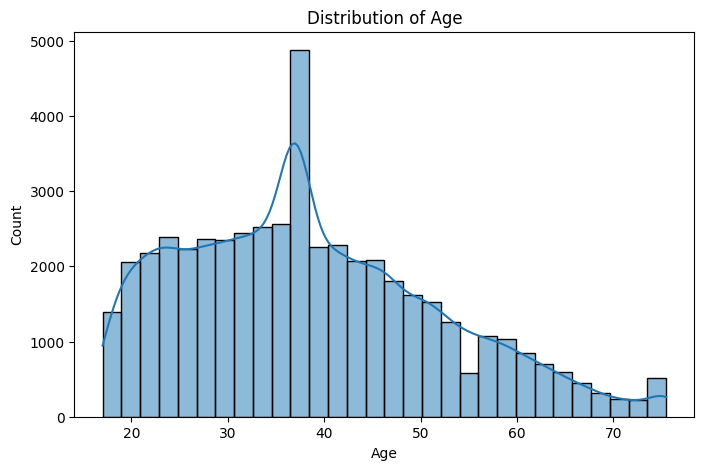

In [21]:
# Distribution of Age
plt.figure(figsize=(8, 5))
sns.histplot(df['age'], bins=30, kde=True)
plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

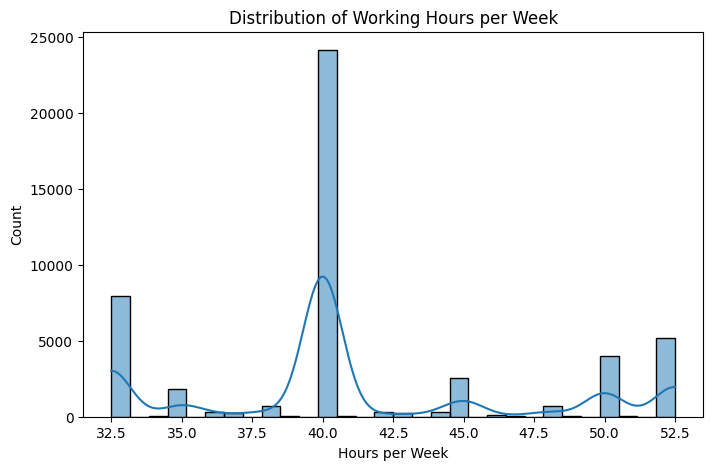

In [22]:
# Distribution of Hours per Week
plt.figure(figsize=(8, 5))
sns.histplot(df['hours-per-week'], bins=30, kde=True)
plt.title("Distribution of Working Hours per Week")
plt.xlabel("Hours per Week")
plt.ylabel("Count")
plt.show()

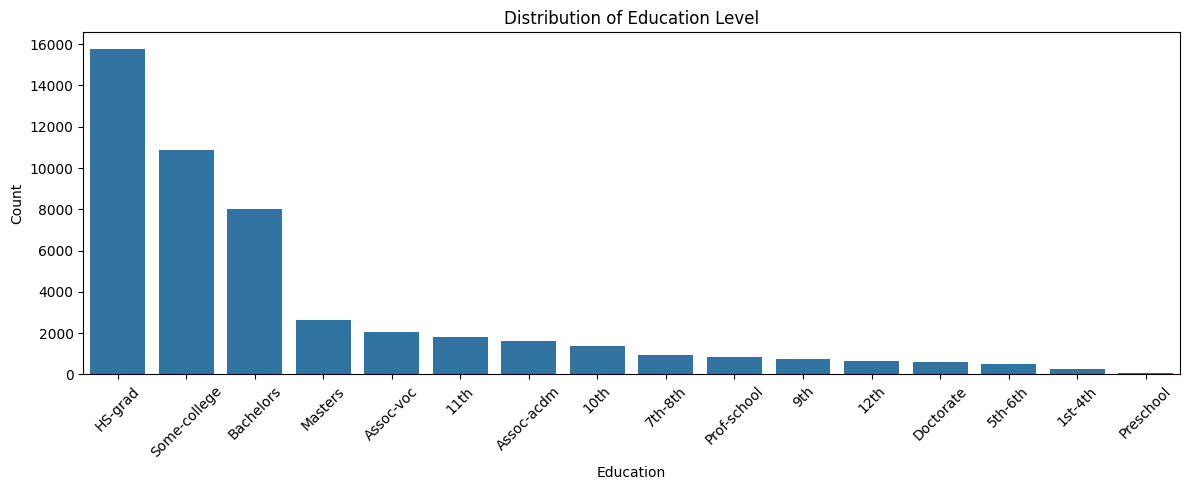

In [23]:
# Distribution of Education Level
plt.figure(figsize=(12, 5))
sns.countplot(data=df, x='education', order=df['education'].value_counts().index)
plt.title("Distribution of Education Level")
plt.xlabel("Education")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Skewness of capital-gain: 11.894658996587946
Skewness of capital-loss: 4.569808857738485


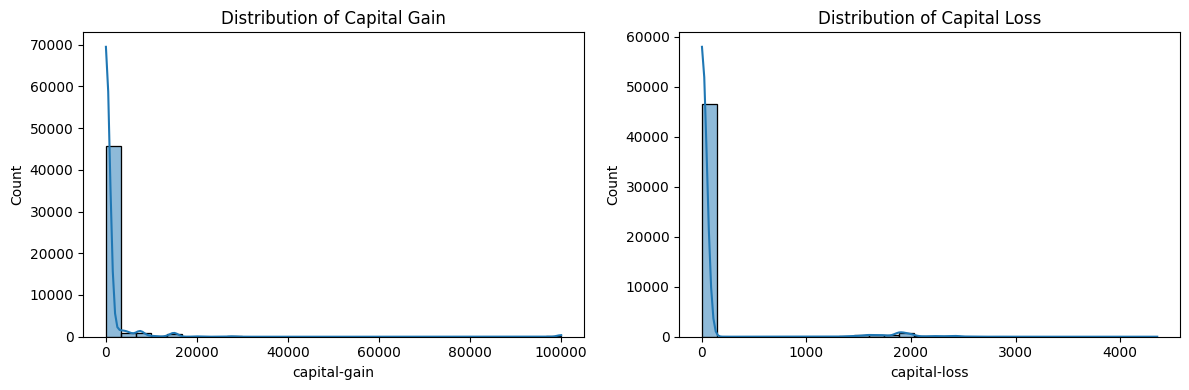

In [24]:
# Skewness of Capital Gain and Capital Loss
print("Skewness of capital-gain:", df['capital-gain'].skew())
print("Skewness of capital-loss:", df['capital-loss'].skew())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['capital-gain'], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Capital Gain")

sns.histplot(df['capital-loss'], bins=30, kde=True, ax=axes[1])
axes[1].set_title("Distribution of Capital Loss")

plt.tight_layout()
plt.show()

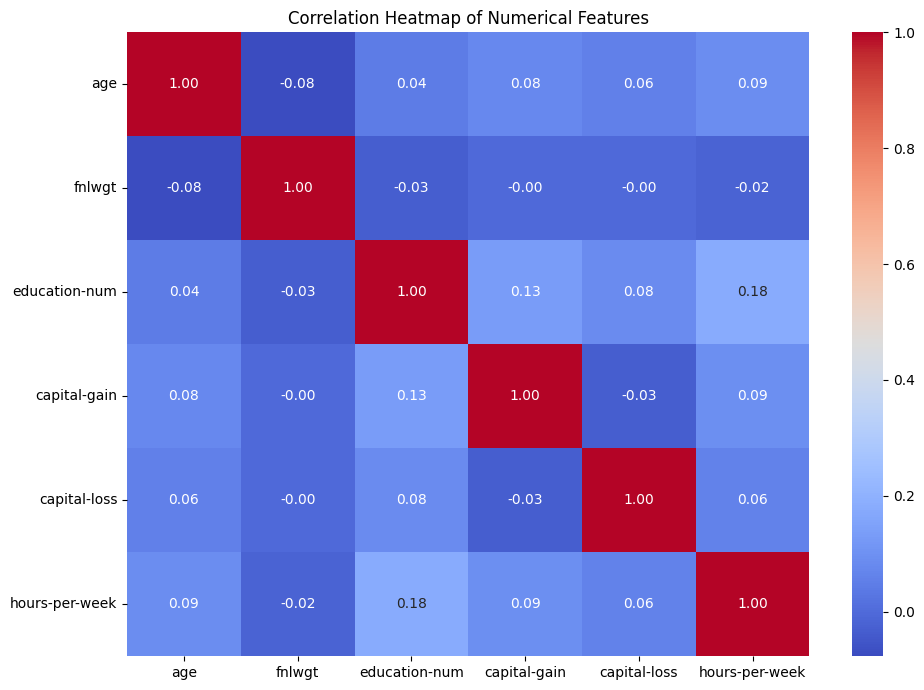

In [25]:
# Correlation among numerical features
plt.figure(figsize=(10, 7))
correlation_matrix = df[numerical_columns].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

The correlation heatmap shows that most numerical features have weak linear relationships with each other. The highest positive correlation is observed between education-num and hours-per-week (0.18).

In [26]:
# k-means Clustering

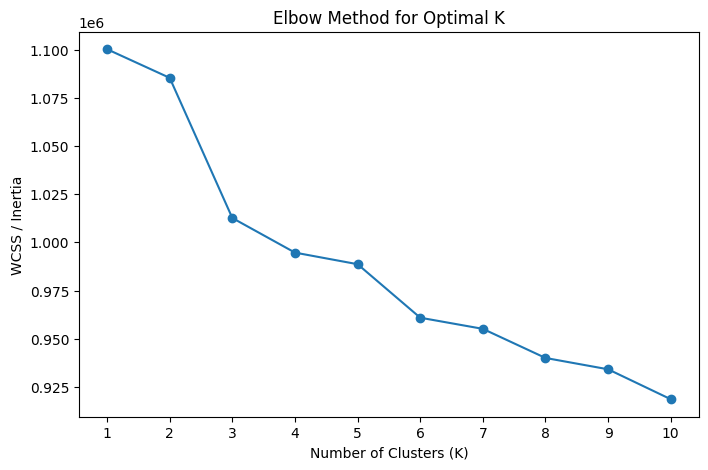

In [27]:
# Elbow method
elbow_sample_size = min(10000, len(scaled_features))
elbow_indices = np.random.RandomState(42).choice(
    len(scaled_features), size=elbow_sample_size, replace=False
)
elbow_data = scaled_features[elbow_indices]

wcss = []
k_values = range(1, 11)

for k in k_values:
    kmeans_temp = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=42
    )
    kmeans_temp.fit(elbow_data)
    wcss.append(kmeans_temp.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(k_values, wcss, marker='o')
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS / Inertia")
plt.xticks(list(k_values))
plt.show()

K = 2  Silhouette Score = 0.0639
K = 3  Silhouette Score = 0.0635
K = 4  Silhouette Score = 0.0494
K = 5  Silhouette Score = 0.0697
K = 6  Silhouette Score = 0.0462
K = 7  Silhouette Score = 0.0655


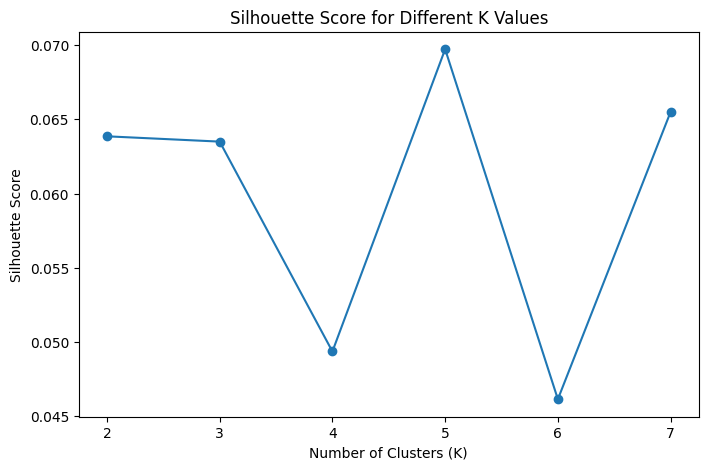

In [28]:
# silhouette Score for selecting k
silhouette_sample_size = min(3000, len(scaled_features))
silhouette_indices = np.random.RandomState(42).choice(
    len(scaled_features), size=silhouette_sample_size, replace=False
)
silhouette_data = scaled_features[silhouette_indices]

silhouette_values = []

for k in range(2, 8):
    kmeans_temp = KMeans(
        n_clusters=k,
        init='k-means++',
        n_init=10,
        max_iter=300,
        random_state=42
    )
    sample_labels = kmeans_temp.fit_predict(silhouette_data)
    score = silhouette_score(silhouette_data, sample_labels)
    silhouette_values.append(score)
    print("K =", k, " Silhouette Score =", round(score, 4))

plt.figure(figsize=(8, 5))
plt.plot(range(2, 8), silhouette_values, marker='o')
plt.title("Silhouette Score for Different K Values")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 8))
plt.show()

### Selection of Optimal K

Based on the Elbow Method, K=3 was selected as the optimal number of clusters, as the reduction in WCSS begins to slow down around this point. Although K=5 produced a slightly higher Silhouette Score, K=3 was selected considering the Elbow Method and the need for a simpler, interpretable clustering solution.

In [29]:
# Choose k and fit the final k-means model
optimal_k = 3
kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    n_init=15,
    max_iter=300,
    random_state=42
)

kmeans_labels = kmeans.fit_predict(scaled_features)

# Storing cluster labels separately for later comparison and PCA
df['KMeans_Cluster'] = kmeans_labels

print("K-Means clustering completed.")
print(df['KMeans_Cluster'].value_counts().sort_index())

K-Means clustering completed.
KMeans_Cluster
0    19873
1    15779
2    13190
Name: count, dtype: int64


In [30]:
# Analyse k-means clusters
kmeans_summary = df.groupby('KMeans_Cluster').agg({
    'age': 'mean',
    'education-num': 'mean',
    'hours-per-week': 'mean',
    'capital-gain': 'mean',
    'capital-loss': 'mean',
    'fnlwgt': 'mean'
}).round(2)

kmeans_summary['Number of Records'] = df['KMeans_Cluster'].value_counts().sort_index()
kmeans_summary

,age,education-num,hours-per-week,capital-gain,capital-loss,fnlwgt,Number of Records
KMeans_Cluster,,,,,,,
0,43.47,10.35,43.10,1785.91,121.67,184700.16,19873
1,28.04,9.98,39.36,348.10,54.63,193136.56,15779
2,43.65,9.95,40.29,888.54,75.34,182274.97,13190


In [31]:
# Most common categories in each K-Means cluster
for column in categorical_columns:
    print("\nMost common", column, "by K-Means cluster:")
    print(df.groupby('KMeans_Cluster')[column].agg(
        lambda x: x.value_counts().index[0]
    ))


Most common workclass by K-Means cluster:
KMeans_Cluster
0    Private
1    Private
2    Private
Name: workclass, dtype: object

Most common education by K-Means cluster:
KMeans_Cluster
0    HS-grad
1    HS-grad
2    HS-grad
Name: education, dtype: object

Most common marital-status by K-Means cluster:
KMeans_Cluster
0    Married-civ-spouse
1         Never-married
2              Divorced
Name: marital-status, dtype: object

Most common occupation by K-Means cluster:
KMeans_Cluster
0    Prof-specialty
1    Prof-specialty
2    Prof-specialty
Name: occupation, dtype: object

Most common relationship by K-Means cluster:
KMeans_Cluster
0          Husband
1        Own-child
2    Not-in-family
Name: relationship, dtype: object

Most common race by K-Means cluster:
KMeans_Cluster
0    White
1    White
2    White
Name: race, dtype: object

Most common sex by K-Means cluster:
KMeans_Cluster
0      Male
1      Male
2    Female
Name: sex, dtype: object

Most common native-country by K-Means cluste

### K-Means Cluster Interpretation

K-Means successfully divided the dataset into three clusters. The clusters contain a relatively balanced number of observations, allowing the population to be divided into three broad groups based on demographic and employment-related characteristics.

The numerical summaries and most common categorical values provide insights into the characteristics of each group. These clusters can help identify differences in age, education, working hours and other demographic factors.

In [32]:
# Agglomerative Clustering

In [33]:
# Create a representative sample
agglo_sample_size = min(1500, len(scaled_features))
agglo_indices = np.random.RandomState(42).choice(
    len(scaled_features), size=agglo_sample_size, replace=False
)
agglo_data = scaled_features[agglo_indices]

print("Sample size for Agglomerative Clustering:", len(agglo_data))

Sample size for Agglomerative Clustering: 1500


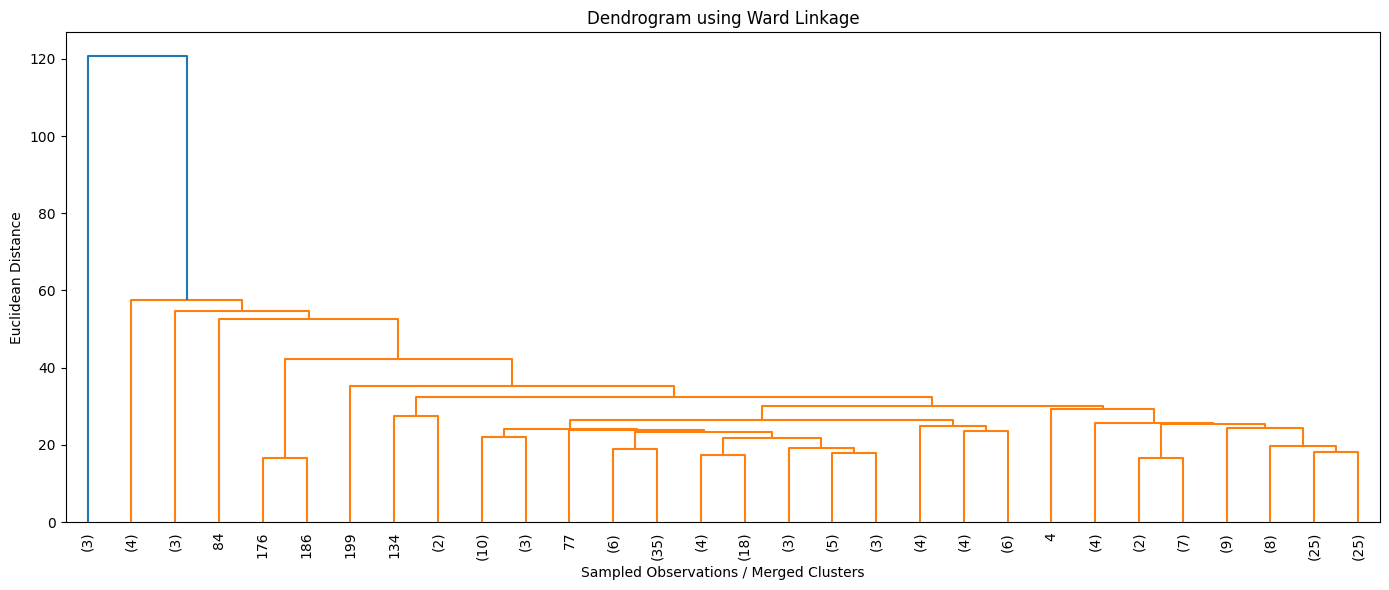

In [34]:
# Generate dendrogram
dendrogram_sample_size = min(200, len(agglo_data))
dendrogram_data = agglo_data[:dendrogram_sample_size]

Z = linkage(dendrogram_data, method='ward')

plt.figure(figsize=(14, 6))
dendrogram(Z, truncate_mode='lastp', p=30, leaf_rotation=90)
plt.title("Dendrogram using Ward Linkage")
plt.xlabel("Sampled Observations / Merged Clusters")
plt.ylabel("Euclidean Distance")
plt.tight_layout()
plt.show()

In [35]:
# Apply agglomerative Clustering
hc = AgglomerativeClustering(
    n_clusters=optimal_k,
    linkage='ward'
)

agglo_labels = hc.fit_predict(agglo_data)

print("Agglomerative clustering completed.")
print(pd.Series(agglo_labels).value_counts().sort_index())

Agglomerative clustering completed.
0    1490
1       3
2       7
Name: count, dtype: int64


In [36]:
agglo_silhouette = silhouette_score(agglo_data, agglo_labels)
print("Agglomerative Silhouette Score (sample):", round(agglo_silhouette, 4))

Agglomerative Silhouette Score (sample): 0.5558


In [37]:
# Analyse agglomerative clusters
agglo_summary_data = df.iloc[agglo_indices][numerical_columns].copy()
agglo_summary_data['Agglomerative_Cluster'] = agglo_labels

agglo_summary = agglo_summary_data.groupby('Agglomerative_Cluster').mean().round(2)
agglo_summary['Number of Records'] = agglo_summary_data[
    'Agglomerative_Cluster'
].value_counts().sort_index()

agglo_summary

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,Number of Records
Agglomerative_Cluster,,,,,,,
0,38.62,186459.68,10.16,923.44,90.97,41.14,1490
1,44.67,197684.33,9.33,0.00,0.00,40.00,3
2,39.43,228698.86,11.71,0.00,227.14,40.36,7


### Agglomerative Clustering Interpretation

Agglomerative Clustering using Ward linkage resulted in highly imbalanced clusters. Most observations were assigned to one cluster, while the other two clusters contained very few observations.

A similar distribution was observed when testing a different random sample. Although the Silhouette Score was relatively high, the highly imbalanced cluster sizes indicate that the result should be interpreted with caution.

In [38]:
# Comparison of k-means and agglomerative clustering

In [39]:
# K-Means labels for the same sample used by Agglomerative Clustering
kmeans_agglo_sample_labels = kmeans_labels[agglo_indices]

comparison = pd.DataFrame({
    'Algorithm': ['K-Means', 'Agglomerative Clustering'],
    'Silhouette Score': [
        silhouette_score(agglo_data, kmeans_agglo_sample_labels),
        agglo_silhouette
    ]
})

comparison

,Algorithm,Silhouette Score
0,K-Means,0.048402
1,Agglomerative Clustering,0.555811


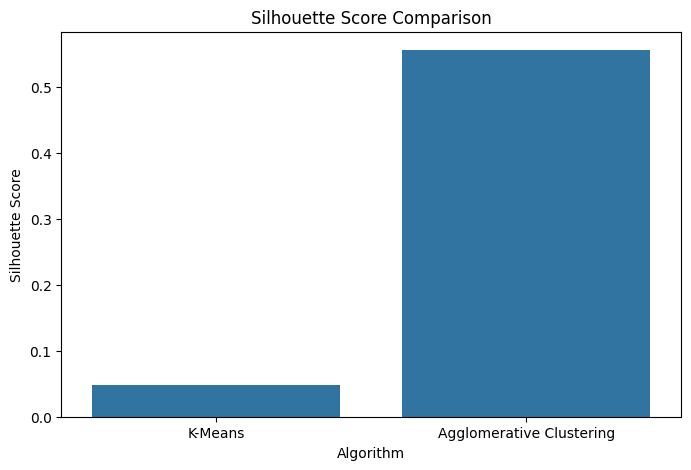

In [40]:
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison, x='Algorithm', y='Silhouette Score')
plt.title("Silhouette Score Comparison")
plt.ylabel("Silhouette Score")
plt.show()

### Comparison of Clustering Algorithms

K-Means produced relatively balanced clusters, whereas Agglomerative Clustering resulted in highly imbalanced clusters.

Although Agglomerative Clustering achieved a higher Silhouette Score, this value may be influenced by the presence of very small clusters. Therefore, the Silhouette Score alone cannot establish that Agglomerative Clustering performed better.

Considering the cluster distribution and the overall results, K-Means provided more balanced population segmentation for this dataset.

In [41]:
# Dimensionality Reduction using PCA

In [42]:
# Applying PCA with two components
pca = PCA(n_components=2)
principal_components = pca.fit_transform(scaled_features)

pca_df = pd.DataFrame(
    principal_components,
    columns=['PC1', 'PC2']
)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance explained by first two components:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Explained variance ratio: [0.04302222 0.02796641]
Total variance explained by first two components: 7.1 %


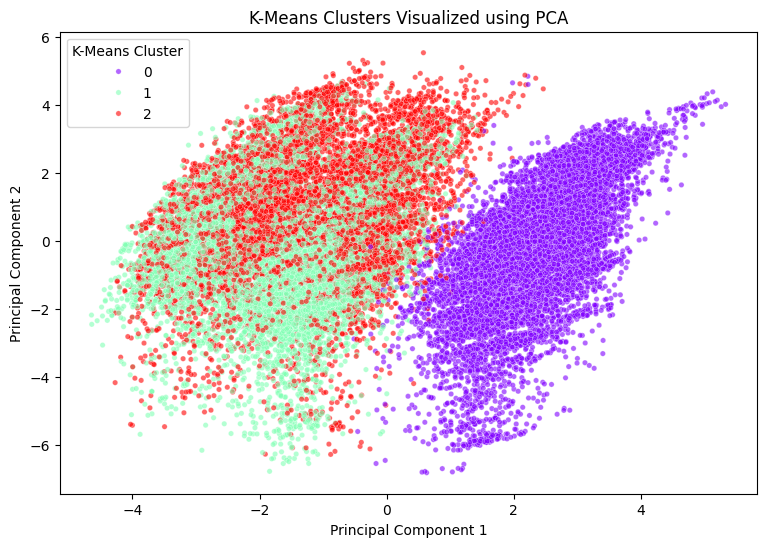

In [43]:
# Visualize k-means clusters in PCA space
pca_df['KMeans_Cluster'] = kmeans_labels

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='KMeans_Cluster',
    palette='rainbow',
    s=15,
    alpha=0.6
)
plt.title("K-Means Clusters Visualized using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title='K-Means Cluster')
plt.show()

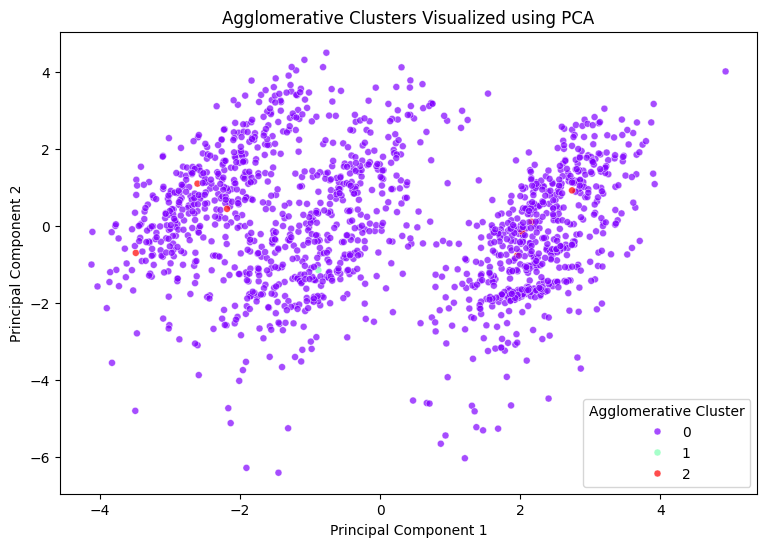

In [44]:
# Visualize agglomerative clusters in PCA space
pca_agglo_df = pca_df.iloc[agglo_indices].copy()
pca_agglo_df['Agglomerative_Cluster'] = agglo_labels

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_agglo_df,
    x='PC1',
    y='PC2',
    hue='Agglomerative_Cluster',
    palette='rainbow',
    s=25,
    alpha=0.7
)
plt.title("Agglomerative Clusters Visualized using PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title='Agglomerative Cluster')
plt.show()

In [45]:
# Explained variance of the principal components
print("PC1 explained variance:", round(pca.explained_variance_ratio_[0] * 100, 2), "%")
print("PC2 explained variance:", round(pca.explained_variance_ratio_[1] * 100, 2), "%")
print("Total explained variance:",
      round(np.sum(pca.explained_variance_ratio_) * 100, 2), "%")

PC1 explained variance: 4.3 %
PC2 explained variance: 2.8 %
Total explained variance: 7.1 %


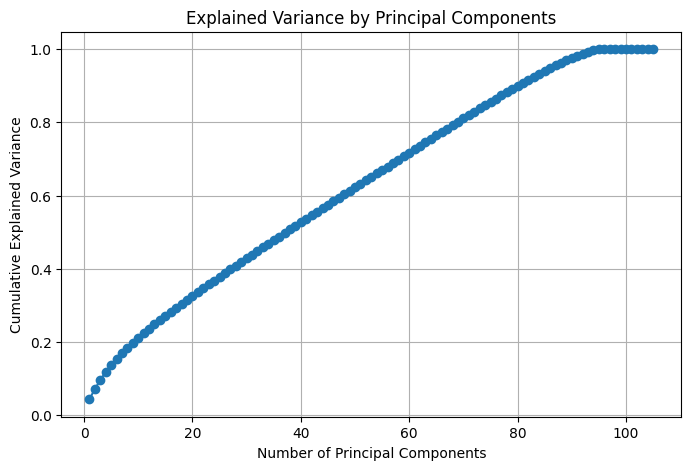

In [46]:
# Plot cumulative explained variance, following the PCA class demonstration
pca_all = PCA()
pca_all.fit(scaled_features)

explained_cumsum = np.cumsum(pca_all.explained_variance_ratio_)

plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(explained_cumsum) + 1),
    explained_cumsum,
    marker='o'
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("Explained Variance by Principal Components")
plt.grid(True)
plt.show()

### PCA Interpretation

1. **How much variance is captured by the first two components?**

   The first two principal components capture approximately **7.10%** of the total variance (PC1: 4.30%, PC2: 2.80%).

2. **Are clusters clearly separable in PCA space?**

   No. The clusters show considerable overlap and are not clearly separable in the two-dimensional PCA plots.

3. **Do both clustering methods show similar separation patterns?**

   Both methods show overlapping clusters. However, their cluster distributions differ, with K-Means producing relatively balanced clusters and Agglomerative Clustering producing highly imbalanced clusters.

# Final Findings and Strategic Workforce Recommendations

## 1. Final Findings

The clustering analysis was performed on 48,842 census records using demographic and employment-related features. The income column was excluded from the clustering process to identify natural population segments without using predefined income categories.

K-Means clustering with three clusters provided relatively balanced groups:

- Cluster 0: 19,873 records
- Cluster 1: 15,779 records
- Cluster 2: 13,190 records

The analysis revealed the following characteristics:

**Cluster 0 – Older, Established Working Group**

- Average age: 43.47 years
- Average education level: 10.35
- Average working hours: 43.10 hours per week
- Most common marital status: Married-civ-spouse
- Most common relationship: Husband
- Highest average capital gain among the three clusters

**Cluster 1 – Younger Working-Age Group**

- Average age: 28.04 years
- Average education level: 9.98
- Average working hours: 39.36 hours per week
- Most common marital status: Never-married
- Most common relationship: Own-child
- Lowest average capital gain and capital loss

**Cluster 2 – Older, Independent Household Group**

- Average age: 43.65 years
- Average education level: 9.95
- Average working hours: 40.29 hours per week
- Most common marital status: Divorced
- Most common relationship: Not-in-family
- Average working hours close to the standard full-time working week

Across all three clusters, Private workclass, HS-grad education, Prof-specialty occupation and United-States native-country were the most frequently occurring categories.

The results show that age, marital status, relationship status and working patterns contribute to differences between the identified groups.


## 2. Strategic Workforce Recommendations

Based on the characteristics of the three clusters, the following workforce development strategies can be considered:

**For Cluster 0 – Older, Established Working Group**

- Provide opportunities for advanced skill development and professional upskilling.
- Encourage continuous learning to help workers adapt to changing workplace technologies.
- Promote flexible working arrangements and career development opportunities.

**For Cluster 1 – Younger Working-Age Group**

- Introduce entry-level skill development and vocational training programmes.
- Provide career guidance, mentoring and employment-readiness programmes.
- Improve access to technical education and opportunities for professional growth.

**For Cluster 2 – Older, Independent Household Group**

- Provide opportunities for reskilling and career advancement.
- Encourage flexible employment and professional development programmes.
- Improve access to career guidance and employment support services.

**Overall Recommendations**

- Develop inclusive skill development programmes that address the needs of different working-age groups.
- Promote continuous learning and digital skill development.
- Use demographic and employment patterns to support workforce planning.
- Periodically evaluate workforce development initiatives to identify changing skill requirements.